# 04 · Variational Circuits

**The quantum neural network.** A variational quantum circuit (VQC) is a parameterized ansatz whose angles are trained by gradient descent to minimize a classification cost. The gradient comes from the **parameter-shift rule** — an *exact* gradient that plays the role backprop plays for a neural net.

We check the parameter-shift gradient against finite differences, train on a small task, and put logistic regression and a small MLP beside it. The link to `backprop_101` and `gradient_descent_101`: it is the same gradient descent, on circuit parameters.

In [ ]:
import sys, json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

# Resolve the repo root whether this runs from the repo root or notebooks/.
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

FIG = ROOT / "outputs" / "figures"
DATA = ROOT / "outputs" / "data"
FIG.mkdir(parents=True, exist_ok=True)
DATA.mkdir(parents=True, exist_ok=True)


def _ser(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, complex):
        return {"re": float(o.real), "im": float(o.imag)}
    raise TypeError(f"not JSON-serializable: {type(o)!r}")


def save_json(name, obj):
    """Save textual/numerical results to outputs/data/<name>."""
    path = DATA / name
    path.write_text(json.dumps(obj, indent=2, default=_ser))
    print("saved", path.relative_to(ROOT))


def save_fig(fig, name):
    """Save a figure as PNG to outputs/figures/<name>."""
    path = FIG / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("saved", path.relative_to(ROOT))


def amp_list(state):
    """A statevector as a JSON-friendly list of {re, im} amplitudes."""
    return [{"re": float(a.real), "im": float(a.imag)} for a in np.asarray(state)]


plt.rcParams.update({"figure.figsize": (7.0, 4.0), "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(42)
print("repo root:", ROOT)


repo root: /workspaces/quantum_ml_101


## The ansatz

Angle-encode $x$, then apply layers of trainable $R_Y$ rotations with a ring of CNOTs, and measure $\langle Z\rangle$ on qubit 0 (a number in $[-1, 1]$ we read as a class score).

In [2]:
from src.qml.vqc import make_circuit, init_params, gradient, finite_diff_gradient

n_qubits, n_layers = 2, 3
circuit = make_circuit(n_qubits, n_layers)
params = init_params(n_qubits, n_layers, rng)
print('parameter shape:', np.asarray(params).shape)
print('one forward pass <Z>:', float(circuit(params, np.array([0.5, 1.2]))))

parameter shape: (3, 2)
one forward pass <Z>: -0.19266765474131065


## Parameter-shift == finite differences

The parameter-shift rule gives the exact gradient from two extra circuit evaluations per parameter. It must agree with a numerical finite-difference gradient — if it does, we can trust it to train the circuit. (This is the asserted claim in the test suite.)

max |parameter-shift - finite-difference|: 2.22e-09
saved outputs/figures/04_gradient_check.png
saved outputs/data/04_gradient_check.json


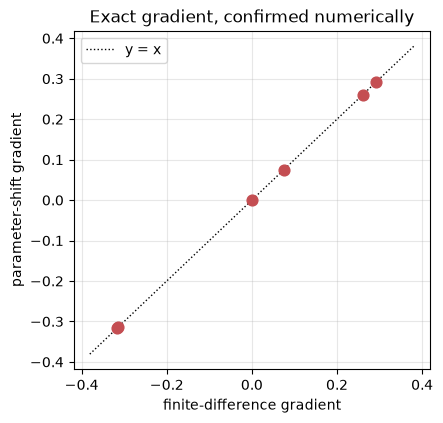

In [3]:
X = rng.uniform(0.0, np.pi, size=(6, n_qubits))
y = np.array([-1.0, 1.0, -1.0, 1.0, -1.0, 1.0])

g_shift = gradient(circuit, params, X, y).ravel()
g_fd = finite_diff_gradient(circuit, params, X, y).ravel()
max_diff = float(np.max(np.abs(g_shift - g_fd)))
print('max |parameter-shift - finite-difference|:', f'{max_diff:.2e}')
assert max_diff < 1e-5

lim = float(np.max(np.abs(g_fd))) * 1.2
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.plot([-lim, lim], [-lim, lim], 'k:', lw=1, label='y = x')
ax.scatter(g_fd, g_shift, s=60, color='#c44e52', zorder=3)
ax.set_xlabel('finite-difference gradient')
ax.set_ylabel('parameter-shift gradient')
ax.set_title('Exact gradient, confirmed numerically')
ax.legend()
save_fig(fig, '04_gradient_check.png')

save_json('04_gradient_check.json', {
    'n_parameters': int(g_shift.size),
    'parameter_shift': g_shift.tolist(),
    'finite_difference': g_fd.tolist(),
    'max_abs_diff': max_diff,
})

## Training: gradient descent on circuit parameters

Minimize the mean-squared cost on a small dataset and watch the loss fall. This is exactly how a neural net trains — only the parameters live in a quantum circuit.

loss: 1.1602 -> 0.4743
saved outputs/figures/04_training_loss.png
saved outputs/data/04_training_loss.json


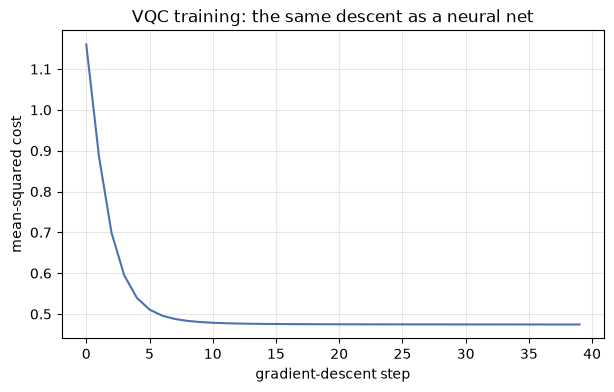

In [4]:
from src.datasets.toy import moons
from src.qml.train import train_vqc

Xtrain, ytrain = moons(n_samples=40, seed=1)
ypm = np.where(ytrain <= 0, -1.0, 1.0)

circuit_t = make_circuit(2, 3)
p0 = init_params(2, 3, np.random.default_rng(0))
p_final, history = train_vqc(circuit_t, p0, Xtrain, ypm, steps=40, lr=0.4)
print('loss:', round(history[0], 4), '->', round(history[-1], 4))

fig, ax = plt.subplots()
ax.plot(history, color='#4c72b0')
ax.set_xlabel('gradient-descent step')
ax.set_ylabel('mean-squared cost')
ax.set_title('VQC training: the same descent as a neural net')
save_fig(fig, '04_training_loss.png')

save_json('04_training_loss.json', {
    'loss_history': [float(v) for v in history],
    'initial_loss': float(history[0]),
    'final_loss': float(history[-1]),
})

## The arena: VQC vs logistic regression vs a small MLP

Same split, same metric. The VQC trains and classifies — and the classical baselines match or beat it, at a tiny fraction of the cost.

 logistic: acc=0.792  fit=0.00s
      mlp: acc=0.792  fit=0.19s


/workspaces/quantum_ml_101/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


      vqc: acc=0.875  fit=43.53s
saved outputs/data/04_arena.json
saved outputs/figures/04_arena_accuracy.png


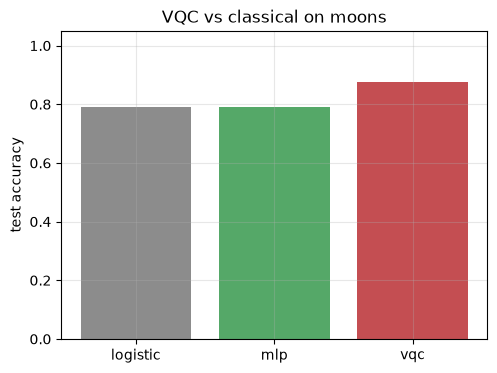

In [5]:
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from src.classical.baselines import logistic, small_mlp
from src.qml.vqc import VQCClassifier
import time

X, y = moons(n_samples=80, seed=0)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

models = {
    'logistic': logistic(),
    'mlp': small_mlp(seed=0),
    'vqc': VQCClassifier(n_qubits=2, n_layers=3, steps=40, lr=0.4, seed=0),
}
arena = {}
for name, model in models.items():
    t0 = time.perf_counter()
    model.fit(Xtr, ytr)
    secs = time.perf_counter() - t0
    acc = float(accuracy_score(yte, model.predict(Xte)))
    arena[name] = {'accuracy': acc, 'fit_seconds': secs}
    print(f'{name:>9}: acc={acc:.3f}  fit={secs:.2f}s')

save_json('04_arena.json', arena)

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.bar(list(arena), [arena[m]['accuracy'] for m in arena], color=['#8c8c8c', '#55a868', '#c44e52'])
ax.set_ylim(0, 1.05)
ax.set_ylabel('test accuracy')
ax.set_title('VQC vs classical on moons')
save_fig(fig, '04_arena_accuracy.png')

## Takeaways

- A VQC is trained exactly like a neural net: gradient descent on parameters.
- The parameter-shift rule is an exact gradient, confirmed against finite diffs.
- On ordinary data, logistic regression and a small MLP match or beat it, far faster.

Next: **05 — The Barren Plateau**, why you cannot simply scale the VQC up.